EDA: EXPLORATORY DATA ANALYSIS

In [1]:
#Loading clean data
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/clean/gaming_clean.csv")

In [2]:
#Market structure
by_state = (df.groupby("state")
              .agg(players=("player_id","count"),
                   total_spend=("spend_inr","sum"),
                   avg_spend=("spend_inr","mean"))
              .sort_values("players", ascending=False))
by_state["share_%"] = (by_state.players / by_state.players.sum() * 100).round(1)
by_state

,players,total_spend,avg_spend,share_%
state,,,,
Uttar Pradesh,159562,5.998669e+08,3759.459333,16.0
Maharashtra,140403,5.247461e+08,3737.427734,14.0
Karnataka,100186,3.756338e+08,3749.364286,10.0
Delhi NCR,90304,3.393277e+08,3757.615336,9.0
Telangana,80104,3.002561e+08,3748.327908,8.0
Tamil Nadu,79842,2.996756e+08,3753.358434,8.0
Bihar,79700,2.989917e+08,3751.463630,8.0
Rajasthan,70282,2.636579e+08,3751.428605,7.0
West Bengal,70000,2.625332e+08,3750.474433,7.0


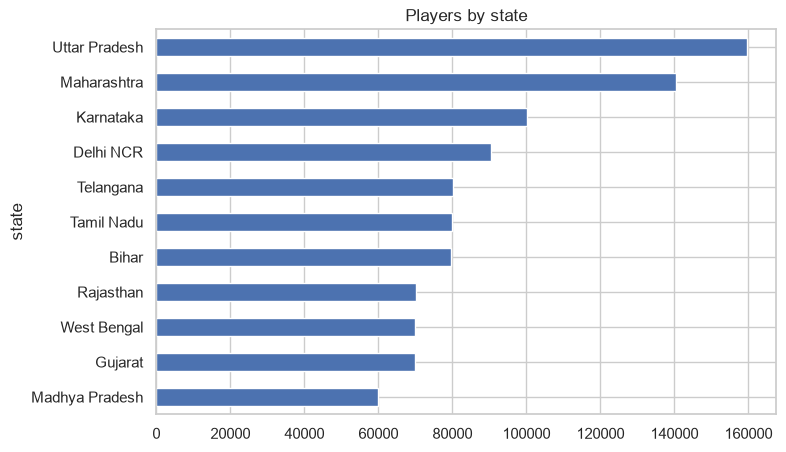

In [3]:
by_state.players.plot(kind="barh", figsize=(8,5), title="Players by state")
plt.gca().invert_yaxis(); plt.savefig("../outputs/charts/players_by_state.png", dpi=150, bbox_inches="tight")

Players by state:	Uttar Pradesh has the most players (16.0%), followed by Maharashtra (14.0%) and Karnataka (10.0%), while Madhya Pradesh has the fewest (6.0%).


In [4]:
by_platform = (df.groupby("platform")
                 .agg(players=("player_id","count"),
                      total_spend=("spend_inr","sum"),
                      avg_spend=("spend_inr","mean"))
                 .sort_values("players", ascending=False))
by_platform["share_%"] = (by_platform.players / by_platform.players.sum() * 100).round(1)
by_platform

,players,total_spend,avg_spend,share_%
platform,,,,
Mobile (Android/iOS),779480,2.922240e+09,3748.961420,77.9
PC (Steam/Epic Games),139878,5.244360e+08,3749.238958,14.0
Console (PS5/Xbox),60455,2.275113e+08,3763.317087,6.0
Cloud Gaming,20171,7.605350e+07,3770.437732,2.0


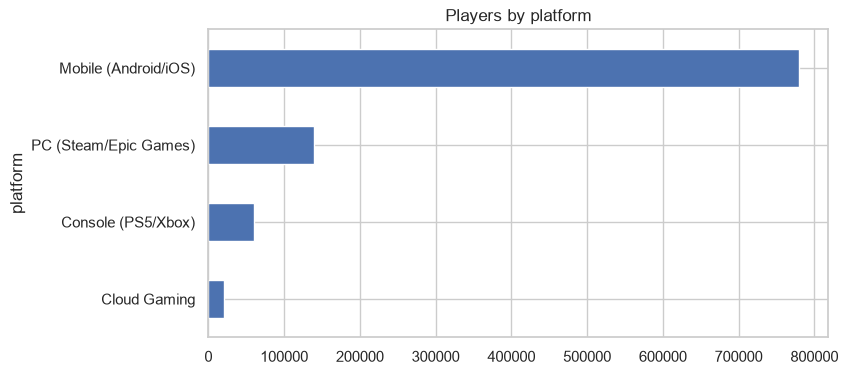

In [5]:
by_platform.players.plot(kind="barh", figsize=(8,4), title="Players by platform")
plt.gca().invert_yaxis()
plt.savefig("../outputs/charts/players_by_platform.png", dpi=150, bbox_inches="tight")

Players by platform:	Mobile dominates with 77.9% of players, ahead of PC (14.0%), Console (6.0%) and Cloud Gaming (2.0%).

In [6]:
by_genre = (df.groupby("genre")
              .agg(players=("player_id","count"),
                   total_spend=("spend_inr","sum"),
                   avg_spend=("spend_inr","mean"))
              .sort_values("players", ascending=False))
by_genre["share_%"] = (by_genre.players / by_genre.players.sum() * 100).round(1)
by_genre

,players,total_spend,avg_spend,share_%
genre,,,,
Battle Royale (BGMI/Free Fire),380396,1.426048e+09,3748.850796,38.0
Esports & Tactical Shooters (Valorant/CS),219840,8.241007e+08,3748.638334,22.0
Cricket & Sports Simulation,159713,5.997438e+08,3755.134830,16.0
Action-RPG & Souls-like,140165,5.263977e+08,3755.557535,14.0
"Casual, Puzzle & Strategy",99870,3.739513e+08,3744.380279,10.0


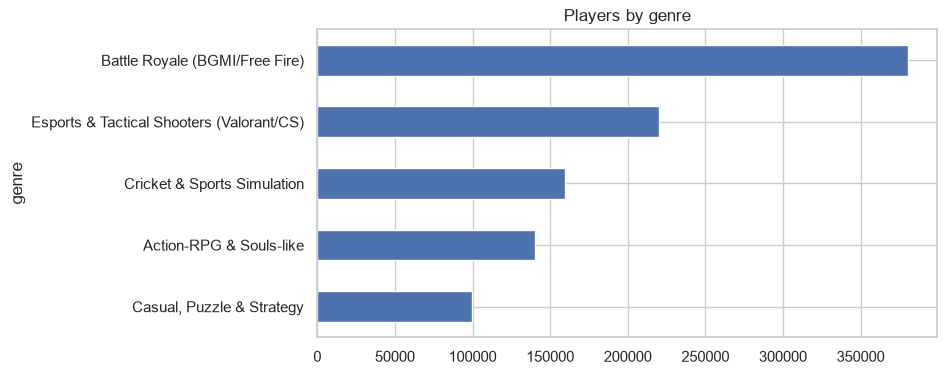

In [9]:
by_genre.players.plot(kind="barh", figsize=(8,4), title="Players by genre")
plt.gca().invert_yaxis()
plt.savefig("../outputs/charts/players_by_genre.png", dpi=150, bbox_inches="tight")

Players by genre:	Battle Royale is the biggest genre at 38.0% of players, and Casual, Puzzle & Strategy is the smallest at 10.0%.

platform,Cloud Gaming,Console (PS5/Xbox),Mobile (Android/iOS),PC (Steam/Epic Games)
signup_year,,,,
2021,2.0,6.1,77.8,14.1
2022,2.0,6.1,77.9,14.0
2023,2.0,6.0,78.0,14.0
2024,2.0,6.1,78.0,14.0
2025,2.0,6.1,78.0,13.9
2026,2.0,6.0,77.9,14.1


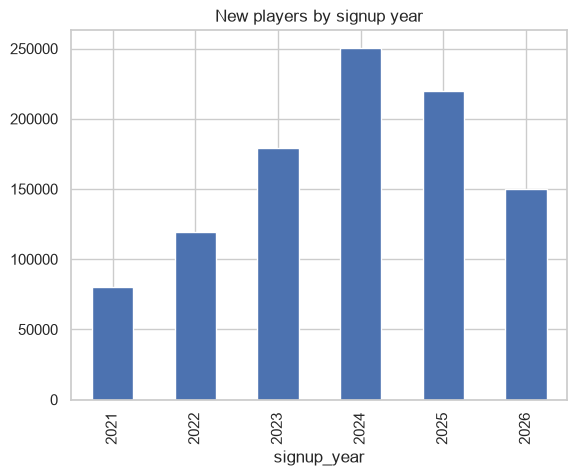

In [11]:
#Growth over time
cohort = df.groupby("signup_year").size()
cohort.plot(kind="bar", title="New players by signup year")

mix = pd.crosstab(df.signup_year, df.platform, normalize="index") * 100
mix.round(1)

Signups grew every year from 80,046 in 2021 to a peak of 250,695 in 2024, then fell to 220,076 in 2025 and 149,996 in 2026.

<Axes: xlabel='genre', ylabel='platform'>

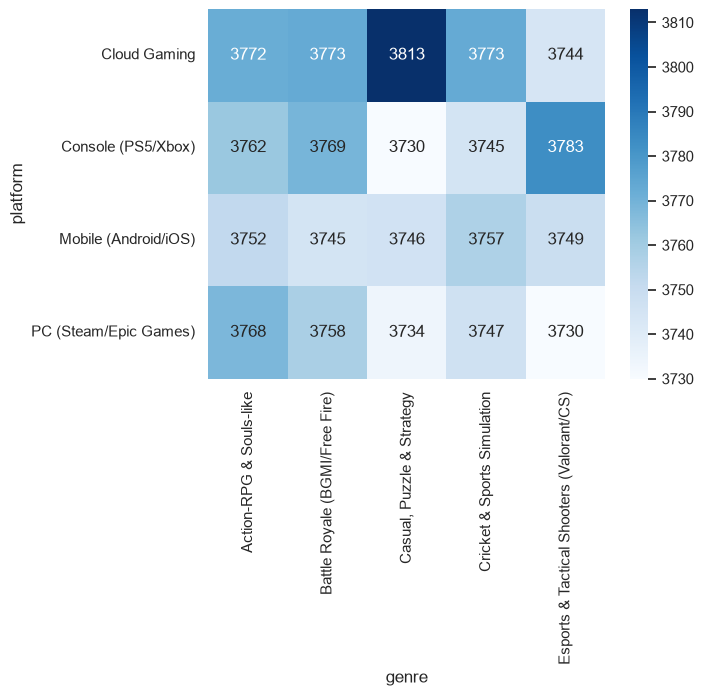

In [12]:
#Monetisation
pivot = df.pivot_table(index="platform", columns="genre",
                       values="spend_inr", aggfunc="mean").round(0)
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")

Average spend is about ₹3,750 in every group, so total revenue follows player count rather than spend per player.
Average spend in every platform and genre pair falls between ₹3,730 and ₹3,813, so no combination is clearly more profitable.

In [16]:
#Demographics
df.groupby("age_group")[["daily_hours","spend_inr"]].mean().round(2)


,daily_hours,spend_inr
age_group,,
18-24,2.19,3755.05
25-34,2.21,3756.05
35-47,2.20,3750.59
Under 18,2.21,3734.55


Average hours (2.19–2.21) and spend (₹3,735–₹3,756) are practically the same across all age groups, including players under 18.

In [17]:
df.groupby("gender")[["daily_hours","spend_inr"]].mean().round(2)

,daily_hours,spend_inr
gender,,
Female,2.20,3746.70
Male,2.20,3752.08
Other,2.21,3749.36


Male, female and other players show nearly identical hours (about 2.20) and spend (about ₹3,750).

array([[<Axes: title={'center': 'daily_hours'}>,
        <Axes: title={'center': 'spend_inr'}>]], dtype=object)

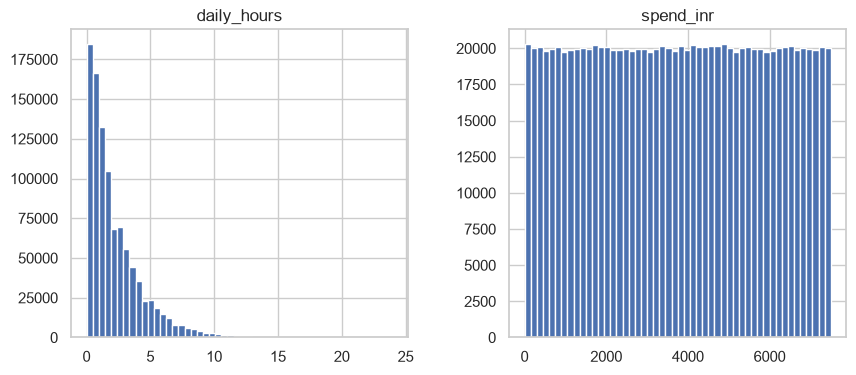

In [20]:
#Distribution and correlation
df[["daily_hours","spend_inr"]].hist(bins=50, figsize=(10,4))


Play time is heavily right-skewed with a median of 1.5 hours; about 75% of players play 3 hours or less, and only 6% play more than 6 hours.
Spend is spread evenly from ₹0 to ₹7,500, with a mean (₹3,750) and median (₹3,755) that are almost the same.

<Axes: >

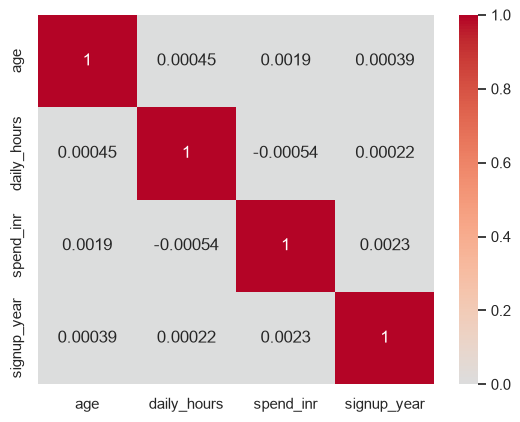

In [21]:
sns.heatmap(df[["age","daily_hours","spend_inr","signup_year"]].corr(),
            annot=True, cmap="coolwarm", center=0)

Age, daily hours, spend and signup year have correlations of about 0, which means none of them predicts another.

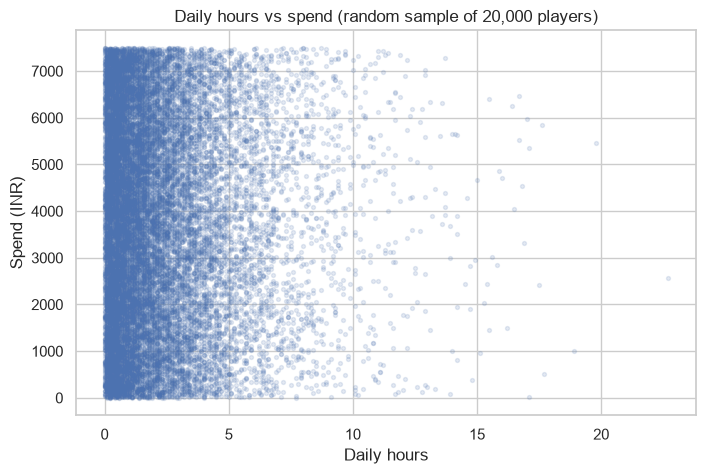

Correlation: -0.0005


In [22]:
sample = df.sample(20000, random_state=42)

plt.figure(figsize=(8,5))
plt.scatter(sample.daily_hours, sample.spend_inr, alpha=0.15, s=8)
plt.xlabel("Daily hours")
plt.ylabel("Spend (INR)")
plt.title("Daily hours vs spend (random sample of 20,000 players)")
plt.savefig("../outputs/charts/hours_vs_spend.png", dpi=150, bbox_inches="tight")
plt.show()

# the number behind the picture
print("Correlation:", round(df.daily_hours.corr(df.spend_inr), 4))

Spending shows no relationship with play time, so heavy players don't spend more than light players.